# Ensembles, complément sur les listes, chaînes de caractères,  

## Ensembles
Commencez par lire le paragraphe 5.4 à l'adresse https://docs.python.org/fr/3/tutorial/datastructures.html#sets.

**Exercice 1.** Créez dans la cellule suivante une liste de 1000 entiers aléatoires entre 1 et 10.

In [1]:
import random
lis = [random.randint(1,10) for i in range(1000)]

**Exercice 2.** Grâce à un changement de type, récupérez dans une variable les modalités (au sens statistique du terme = liste des valeurs prises) de lis. Affichez le nombre de modalités et les modalités.

In [2]:
modalites = set(lis)
print("nombre de modalités = ", len(modalites))
print("modalités =", list(modalites))

nombre de modalités =  10
modalités = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


**Exercice 3.** Il est possible d'ajouter des éléments dans un ensemble grâce à la méthode *add*.
Avec une approche générique, calculez les modalités de *lis* dans la cellule suivante et affichez-les pour vérification. Il vous faudra chercher comment initialiser un ensemble vide.

In [3]:
s = set()
for i in range(len(lis)):
    s.add(lis[i])
print(s)

{1, 2, 3, 4, 5, 6, 7, 8, 9, 10}


**Exercice 4.** On peut aussi créer des ensembles par compréhension. Calculer la liste de modalités par ce biais et affichez-la pour vérification.

In [4]:
print(list({lis[i] for i in range(len(lis))}))

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


**Exercice 5.** Complétez la fonction suivante.

In [5]:
def copie_sans_doublon( lis ):
    """
    retourne une copie sans doublon de la liste lis
    """
    # corps à écrire ici en une ligne
    return list(set(lis))

In [6]:
# Test de la fonction (vous pouvez ajouter des tests)
from aide_test import *
liste_tests = [ ([3, 2, 5, 2, 3, 2], [2, 3, 5], "test quelconque"),
                ([],[], "liste vide")]
test(copie_sans_doublon, liste_tests)

0 problème(s) sur 2 tests


De manière plus générique, une bonne méthode pour résoudre le problème résolu par la fonction *copie_sans_doublon()* consiste à :
* commencer par trier la liste initiale (ou à calculer une copie triée de la liste si on ne veut pas modifier la liste) puis, 
* une fois la liste triée, on peut créer une liste des valeurs différentes des valeurs qui les précèdent immédiatement (la liste des *lis[i]* avec *lis[i]* différent de *lis[i-1]* si *lis* est la liste triée de travail ; il faut bien entendu ajouter le premier élément si la liste n'est pas vide).

En Python, il est possible de trier une liste grâce à la méthode *sort()* (liste modifiée) ou à l'aide de la fonction *sorted()*.

**Exercice 6.** Complétez la fonction suivante avec l'approche générique décrite précédemment (en utilisant dans la première phase *sort()* ou *sorted()*.

In [7]:
def copie_sans_doublon( lis ):
    """
    retourne une copie sans doublon de la liste lis
    """
    tmp = sorted(lis)
    res = []
    if tmp != []:
        res.append(tmp[0])
        for i in range(1,len(tmp)):
            if tmp[i] != tmp[i-1]:
                res.append(tmp[i])
    return res

In [8]:
# Test de la fonction (vous pouvez ajouter des tests)
liste_tests = [ ([3, 2, 5, 2, 3, 2], [2, 3, 5], "test quelconque"),
                ([],[], "liste vide")]
test(copie_sans_doublon, liste_tests)

0 problème(s) sur 2 tests


## Slicing
* *lis[i:j]* désigne la liste constituée des éléments de l'indice *i* à l'indice *j-1* (en supposant que *i* et *j-1* désignent bien des indices). Dans une expression de calcul, il s'agit d'une copie. Si *lis[i:j]* est à gauche d'un signe d'affectation, cela permet de modifier cette partie de la liste.
* Si *i* n'est pas précisée, la valeur *0* est considérée à la place.
* Si *j* n'est pas précisée, la valeur *len(lis)* est considérée à la place.

**Question 7.** Comment réaliser la copie d'une liste à l'aide d'un slice ?

In [9]:
# Essayez ici votre idée 
lis = [6, 8, 9, 1, 2]
lis2 = lis[:] #???? # remplacez ???? par la copie
print(lis2)

[6, 8, 9, 1, 2]


Remarque. Pour réaliser une copie, on préférera l'utilisation de la méthode *copy( )* de la classe *list* car l'intention sera plus claire.

In [10]:
# test
lis3 = lis.copy()
print(lis3)

[6, 8, 9, 1, 2]


**Exercice 8.** Vérifions que les listes sont bien des copies indépendantes.
Complétez la cellule suivante (n'hésitez pas à regardez la documentation en ligne ou le tutoriel Python).

In [11]:
lis[1] = 5 #... # Remplacement dans lis de la valeur à l'indice 1 par la valeur 5
lis2[1:4] = [] # ... # Suppression des 3 éléments centraux de la liste lis2 à l'aide d'un slice
del(lis3[-1]) # ... # Suppression du dernier élément de la liste lis3 avec del
lis3.remove(6) # ... # Suppression de la valeur 6 dans la liste lis3
print("lis  :", lis)
print("lis2 :", lis2)
print("lis3 :", lis3)

lis  : [6, 5, 9, 1, 2]
lis2 : [6, 2]
lis3 : [8, 9, 1]


**Exercice 9.** Complétez la fonction suivante avec une approche générique. Déduisez en une estimation du coût de l'opération de slicing (pour cela vous pouvez aussi regarder la page https://wiki.python.org/moin/TimeComplexity).

In [12]:
def slice( lis, i, j):
    """
    Retourne lis[i:j]
    
    lis : liste
    i, j : entiers vérifiant 0 <= i <= j < len(lis)
    """
    res = []
    for k in range(i, j, 1):
        res.append(lis[k])
    return res

In [13]:
# Test de la fonction (vous pouvez ajouter des tests)
from aide_test import *
liste_tests = [ (([3, 2, 5, 2, 3, 2], 1, 4), [2, 5, 2], "test quelconque"),
                (([], 0, 0),[], "liste vide"),
                (([1, 2, 3], 0, 3), [1, 2, 3], "liste complète")]
test(slice, liste_tests)

0 problème(s) sur 3 tests


Une question naturelle est de se demander si l'opération de slicing python est véritablement plus rapide que la méthode générique. Voici un exemple de mesure 

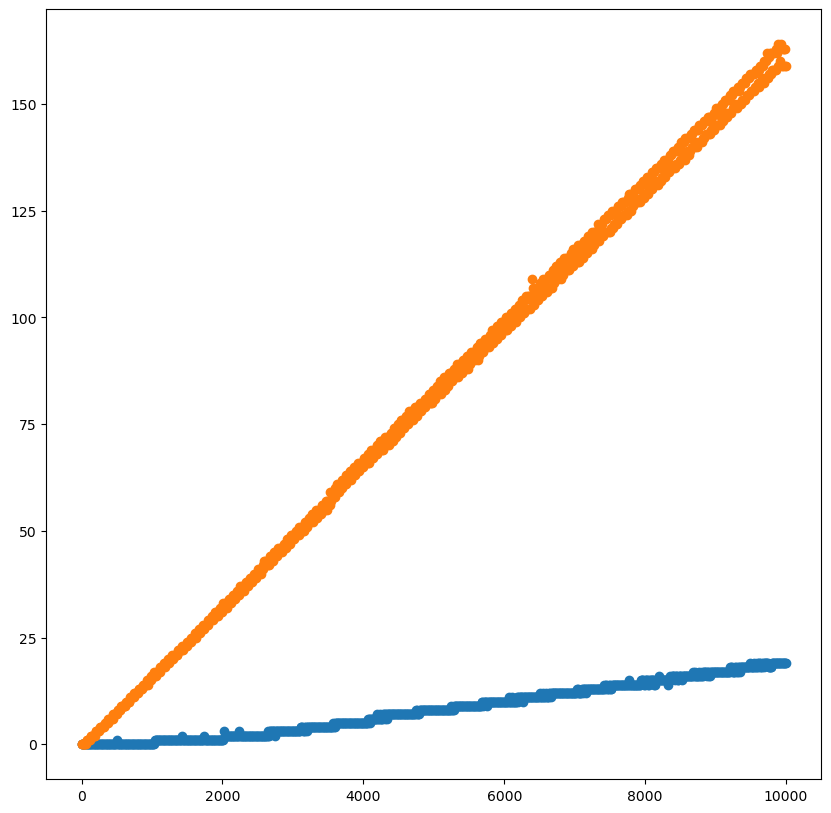

In [14]:
import timeit # module de gestion du temps avec lambda
import random
max_len = 10000
pas_len = 10
nb_repet = 100
lis_alea = [ random.random() for i in range(max_len+1)]
temps_slice = []
for n in range(0, max_len+1, pas_len):
    temps_exec = timeit.timeit(stmt=lambda:lis_alea[:n], 
                           number=nb_repet)
    temps_slice.append(int(temps_exec/nb_repet*1000000))
temps_generique = []
for n in range(0, max_len+1, pas_len):
    temps_exec = timeit.timeit(stmt=lambda:slice( lis_alea, 0, n), 
                           number=nb_repet)
    temps_generique.append(int(temps_exec/nb_repet*1000000))
# La ligne suivante permet l'affichage de la visualisation
    # dans le notebook et non en fenêtre popup
%matplotlib inline  
from matplotlib import pyplot as plt 
figure = plt.figure(figsize=(10, 10))
abscisses = [ n for n in range(0, max_len+1, pas_len)]
plot = plt.scatter(abscisses, temps_slice)
plot = plt.scatter(abscisses, temps_generique)

# Chaînes de caractères
Une chaîne de caractères (type String en Python) peut être vue comme une liste non modifiable de caractères, du moins du point de vue des opérations qu'on peut réaliser dessus. Vous pouvez le vérifier sur https://docs.python.org/fr/3/tutorial/introduction.html#strings.

**Exercice 10.** On appelle sous-chaîne (ou facteur) d'une chaîne une suite consécutive de facteurs. Complétez la fonction suivante.

Vous pourrez aborder le problème de deux manières différentes (utilisez alors deux cellules) :
1. avec une approche générique et deux boucles imbriquées (tout en utilisant la fonction slice (qui doit marcher sur les chaînes de caractères) ou l'opération de slicing elle-même).
2. avec une approche pythonesque en sachant qu'on peut faire varier plusieurs indices dans une définition par compréhension d'un ensemble.

Vous pourrez vous demander quelle est la complexité asymptotique de cette fonction.

In [15]:
# Correction 10.1
def facteurs( ch ):
    """
    calcule et retourne l'ensemble des sous-chaînes d'un mot
    
    Données ch : String
    """
    s = set()
    for i in range(len(ch)+1):
        for j in range(len(ch)+1):
            s.add(ch[i:j])        
    return s

In [16]:
# Correction 10.2
def facteurs( ch ):
    """
    calcule et retourne l'ensemble des sous-chaînes d'un mot
    
    Données ch : String
    """
    return {ch[i:j] for i in range(len(ch)+1) for j in range(len(ch)+1)}

In [17]:
facteurs("")

{''}

In [18]:
from aide_test import *
liste_tests = [ ("",{""},"vide"),
               ("pepe",{'', 'e', 'ep', 'epe', 'p', 'pe', 'pep', 'pepe'},"quelconque"),
               ("python", {'','h','ho','hon','n','o','on', 'p',
                           'py','pyt','pyth','pytho','python',
                           't','th','tho','thon','y','yt','yth',
                           'ytho','ython'},"quelconque")]
test(facteurs, liste_tests)

0 problème(s) sur 3 tests


Nous avons dit que les chaînes de caractères pouvaient être considérées comme des listes non modifiables (mais il y a des différences). On pourrait donc se demander si la fonction *facteurs()* peut s'appliquer à une liste. Testez !

In [19]:
facteurs([1, 2, 3])

TypeError: unhashable type: 'list'

Si vous voulez comprendre le message d'erreur, vous pouvez consulter, par exemple, https://docs.python.org/fr/3.8/library/stdtypes.html#set.

Au cas où vous n'avez pas trouvé la raison du problème : les listes ne sont pas hashables.